### Sprint 3 — EDA: UCI Student Performance Dataset

Exploratory analysis of the raw UCI Student Performance CSVs (`student-mat.csv`, `student-por.csv`)
 this notebook covers:
- G1 / G2 / G3 grade distributions
- Absences
- Failures
- Study time
- Correlations (with a target-leakage check, since G3 must never be used as an input
  feature once `at_risk` is derived from it)

Two related files, same 33 columns:
- `student-mat.csv` — Mathematics, 395 students
- `student-por.csv` — Portuguese language, 649 students

They are **not the same students in two subjects** on a 1:1 basis (some students
appear in both), so we analyze them side by side rather than blindly concatenating.

| Variable Name | Role    | Type        | Demographic     | Description                                                                                                               | Units | Missing Values |
| ------------- | ------- | ----------- | --------------- | ------------------------------------------------------------------------------------------------------------------------- | ----- | -------------- |
| `school`      | Feature | Categorical |                 | Student's school (binary: `'GP'` - Gabriel Pereira or `'MS'` - Mousinho da Silveira)                                      |       | No             |
| `sex`         | Feature | Binary      | Sex             | Student's sex (binary: `'F'` - female or `'M'` - male)                                                                    |       | No             |
| `age`         | Feature | Integer     |                 | Student's age (numeric: from 15 to 22)                                                                                    | Years | No             |
| `address`     | Feature | Categorical |                 | Student's home address type (binary: `'U'` - urban or `'R'` - rural)                                                      |       | No             |
| `famsize`     | Feature | Categorical | Other           | Family size (binary: `'LE3'` - less than or equal to 3 or `'GT3'` - greater than 3)                                       |       | No             |
| `Pstatus`     | Feature | Categorical | Other           | Parent's cohabitation status (binary: `'T'` - living together or `'A'` - apart)                                           |       | No             |
| `Medu`        | Feature | Integer     | Education Level | Mother's education (0 - none, 1 - primary education, 2 - 5th to 9th grade, 3 - secondary education, 4 - higher education) | Level | No             |
| `Fedu`        | Feature | Integer     | Education Level | Father's education (0 - none, 1 - primary education, 2 - 5th to 9th grade, 3 - secondary education, 4 - higher education) | Level | No             |
| `Mjob`        | Feature | Categorical | Occupation      | Mother's job (nominal: `'teacher'`, `'health'` care related, civil `'services'`, `'at_home'`, or `'other'`)               |       | No             |
| `Fjob`        | Feature | Categorical | Occupation      | Father's job (nominal: `'teacher'`, `'health'` care related, civil `'services'`, `'at_home'`, or `'other'`)               |       | No             |
| `reason`      | Feature | Categorical |             | Reason to choose this school (nominal: close to `'home'`, school `'reputation'`, `'course'` preference, or `'other'`) |          | No             |
| `guardian`    | Feature | Categorical |             | Student's guardian (nominal: `'mother'`, `'father'`, or `'other'`)                                                    |          | No             |
| `traveltime`  | Feature | Integer     |             | Home-to-school travel time (1 - <15 min., 2 - 15 to 30 min., 3 - 30 min. to 1 hour, 4 - >1 hour)                      | Category | No             |
| `studytime`   | Feature | Integer     |             | Weekly study time (1 - <2 hours, 2 - 2 to 5 hours, 3 - 5 to 10 hours, 4 - >10 hours)                                  | Category | No             |
| `failures`    | Feature | Integer     |             | Number of past class failures (1–3, with higher values representing 3 or more failures)                               | Count    | No             |
| `schoolsup`   | Feature | Binary      |             | Extra educational support (yes or no)                                                                                 |          | No             |
| `famsup`      | Feature | Binary      |             | Family educational support (yes or no)                                                                                |          | No             |
| `paid`        | Feature | Binary      |             | Extra paid classes within the course subject (Math or Portuguese) (yes or no)                                         |          | No             |
| `activities`  | Feature | Binary      |             | Extra-curricular activities (yes or no)                                                                               |          | No             |
| `nursery`     | Feature | Binary      |             | Attended nursery school (yes or no)                                                                                   |          | No             |
| `higher`      | Feature | Binary      |             | Wants to take higher education (yes or no)                                                                            |          | No             |
| `internet`    | Feature | Binary      |             | Internet access at home (yes or no)                                                                                   |          | No             |
| `romantic`    | Feature | Binary      |             | Currently in a romantic relationship (yes or no)                                                                      |          | No             |
| `famrel`      | Feature | Integer     |             | Quality of family relationships (1 - very bad to 5 - excellent)                                                       | Rating   | No             |
| `freetime`    | Feature | Integer     |             | Free time after school (1 - very low to 5 - very high)                                                                | Rating   | No             |
| `goout`       | Feature | Integer     |             | Going out with friends (1 - very low to 5 - very high)                                                                | Rating   | No             |
| `Dalc`        | Feature | Integer     |             | Workday alcohol consumption (1 - very low to 5 - very high)                                                           | Rating   | No             |
| `Walc`        | Feature | Integer     |             | Weekend alcohol consumption (1 - very low to 5 - very high)                                                           | Rating   | No             |
| `health`      | Feature | Integer     |             | Current health status (1 - very bad to 5 - very good)                                                                 | Rating   | No             |
| `absences`    | Feature | Integer     |             | Number of school absences (0 to 93)                                                                                   | Count    | No             |
| `G1`          | Target  | Integer     |             | First-period grade (0 to 20)                                                                                          | Grade    | No             |
| `G2`          | Target  | Integer     |             | Second-period grade (0 to 20)                                                                                         | Grade    | No             |
| `G3`          | Target  | Integer     |             | Final grade (0 to 20; output target)                                                                                  | Grade    | No             |


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100

PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"

RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw", "uci_data")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)
PASS_THRESHOLD = 10

#### Load files

In [2]:
mat = pd.read_csv(os.path.join(RAW_DIR, "student-mat.csv"), sep=";")
por = pd.read_csv(os.path.join(RAW_DIR, "student-por.csv"), sep=";")

mat["subject"] = "Mathematics"
por["subject"] = "Portuguese"

print(f"student-mat.csv : {mat.shape[0]} rows x {mat.shape[1]} cols")
print(f"student-por.csv : {por.shape[0]} rows x {por.shape[1]} cols")

df = pd.concat([mat, por], ignore_index=True)
print(f"Combined (for side-by-side EDA only, not modeling): {df.shape[0]} rows")


student-mat.csv : 395 rows x 34 cols
student-por.csv : 649 rows x 34 cols
Combined (for side-by-side EDA only, not modeling): 1044 rows


In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Mathematics


In [4]:
df.tail()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
1039,MS,F,19,R,GT3,T,2,3,services,other,course,mother,1,3,1,no,no,no,yes,no,yes,yes,no,5,4,2,1,2,5,4,10,11,10,Portuguese
1040,MS,F,18,U,LE3,T,3,1,teacher,services,course,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,3,4,1,1,1,4,15,15,16,Portuguese
1041,MS,F,18,U,GT3,T,1,1,other,other,course,mother,2,2,0,no,no,no,yes,yes,yes,no,no,1,1,1,1,1,5,6,11,12,9,Portuguese
1042,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,6,10,10,10,Portuguese
1043,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,4,10,11,11,Portuguese


### 2. Shape, dtypes, missing values

In [5]:
print(f"student-mat.csv : {mat.shape[0]} rows x {mat.shape[1]} cols")

mat.info()

student-mat.csv : 395 rows x 34 cols
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     3

In [6]:
por.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [7]:
missing = df.drop(columns="subject").isna().sum()
missing = missing[missing > 0]
print("Missing values across both files:" if len(missing) else "No missing values in either file.")
missing

No missing values in either file.


Series([], dtype: int64)

In [8]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,16.726054,2.603448,2.387931,1.522989,1.970307,0.264368,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,11.213602,11.246169,11.341954
std,1.239975,1.124907,1.099938,0.731727,0.834353,0.656142,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,2.983394,3.285071,3.864796
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000,10.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


#### Reusable EDA helper functions

Outlier detection helper — used in Section 10 below to compute IQR bounds and
skewness for numeric columns.

In [9]:
def outlier_summary(data, col):
    """IQR-based outlier bounds/count + skewness for a numeric column."""
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((data[col] < lower) | (data[col] > upper)).sum()
    return {
        "column": col,
        "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "lower_bound": round(lower, 2), "upper_bound": round(upper, 2),
        "n_outliers": int(n_outliers),
        "pct_outliers": round(n_outliers / len(data) * 100, 2),
        "skewness": round(data[col].skew(), 2),
    }

###  Full categorical & ordinal column inventory

Every non-numeric-grade column in this dataset is either a **true categorical /
binary column** (object dtype — `school`, `sex`, `Mjob`, etc.) or an **ordinal
column encoded as small integers** (`Medu`, `studytime`, `famrel`, etc. — these
are ratings/levels, not counts you'd average meaningfully like a continuous
number). This section prints the exact label set, counts, and percentages for
**every one of them**, so nothing about "what values does this column actually
take" is left implicit.

In [10]:
# True categorical / binary (object dtype) columns
object_cols = df.select_dtypes(include="object").columns.tolist()
object_cols = [c for c in object_cols if c not in ("studytime_label",)]  # derived column, not raw data
print(f"Object-dtype (true categorical) columns: {len(object_cols)}")
print(object_cols)

Object-dtype (true categorical) columns: 18
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'subject']


In [11]:
for col in object_cols:
    vc = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(normalize=True, dropna=False).round(3) * 100
    summary = pd.DataFrame({"count": vc, "pct": pct.round(1)})
    print(f"\n=== {col}  ({df[col].nunique()} unique labels) ===")
    print(summary)


=== school  (2 unique labels) ===
        count   pct
school             
GP        772  73.9
MS        272  26.1

=== sex  (2 unique labels) ===
     count   pct
sex             
F      591  56.6
M      453  43.4

=== address  (2 unique labels) ===
         count   pct
address             
U          759  72.7
R          285  27.3

=== famsize  (2 unique labels) ===
         count   pct
famsize             
GT3        738  70.7
LE3        306  29.3

=== Pstatus  (2 unique labels) ===
         count   pct
Pstatus             
T          923  88.4
A          121  11.6

=== Mjob  (5 unique labels) ===
          count   pct
Mjob                 
other       399  38.2
services    239  22.9
at_home     194  18.6
teacher     130  12.5
health       82   7.9

=== Fjob  (5 unique labels) ===
          count   pct
Fjob                 
other       584  55.9
services    292  28.0
teacher      65   6.2
at_home      62   5.9
health       41   3.9

=== reason  (4 unique labels) ===
            coun

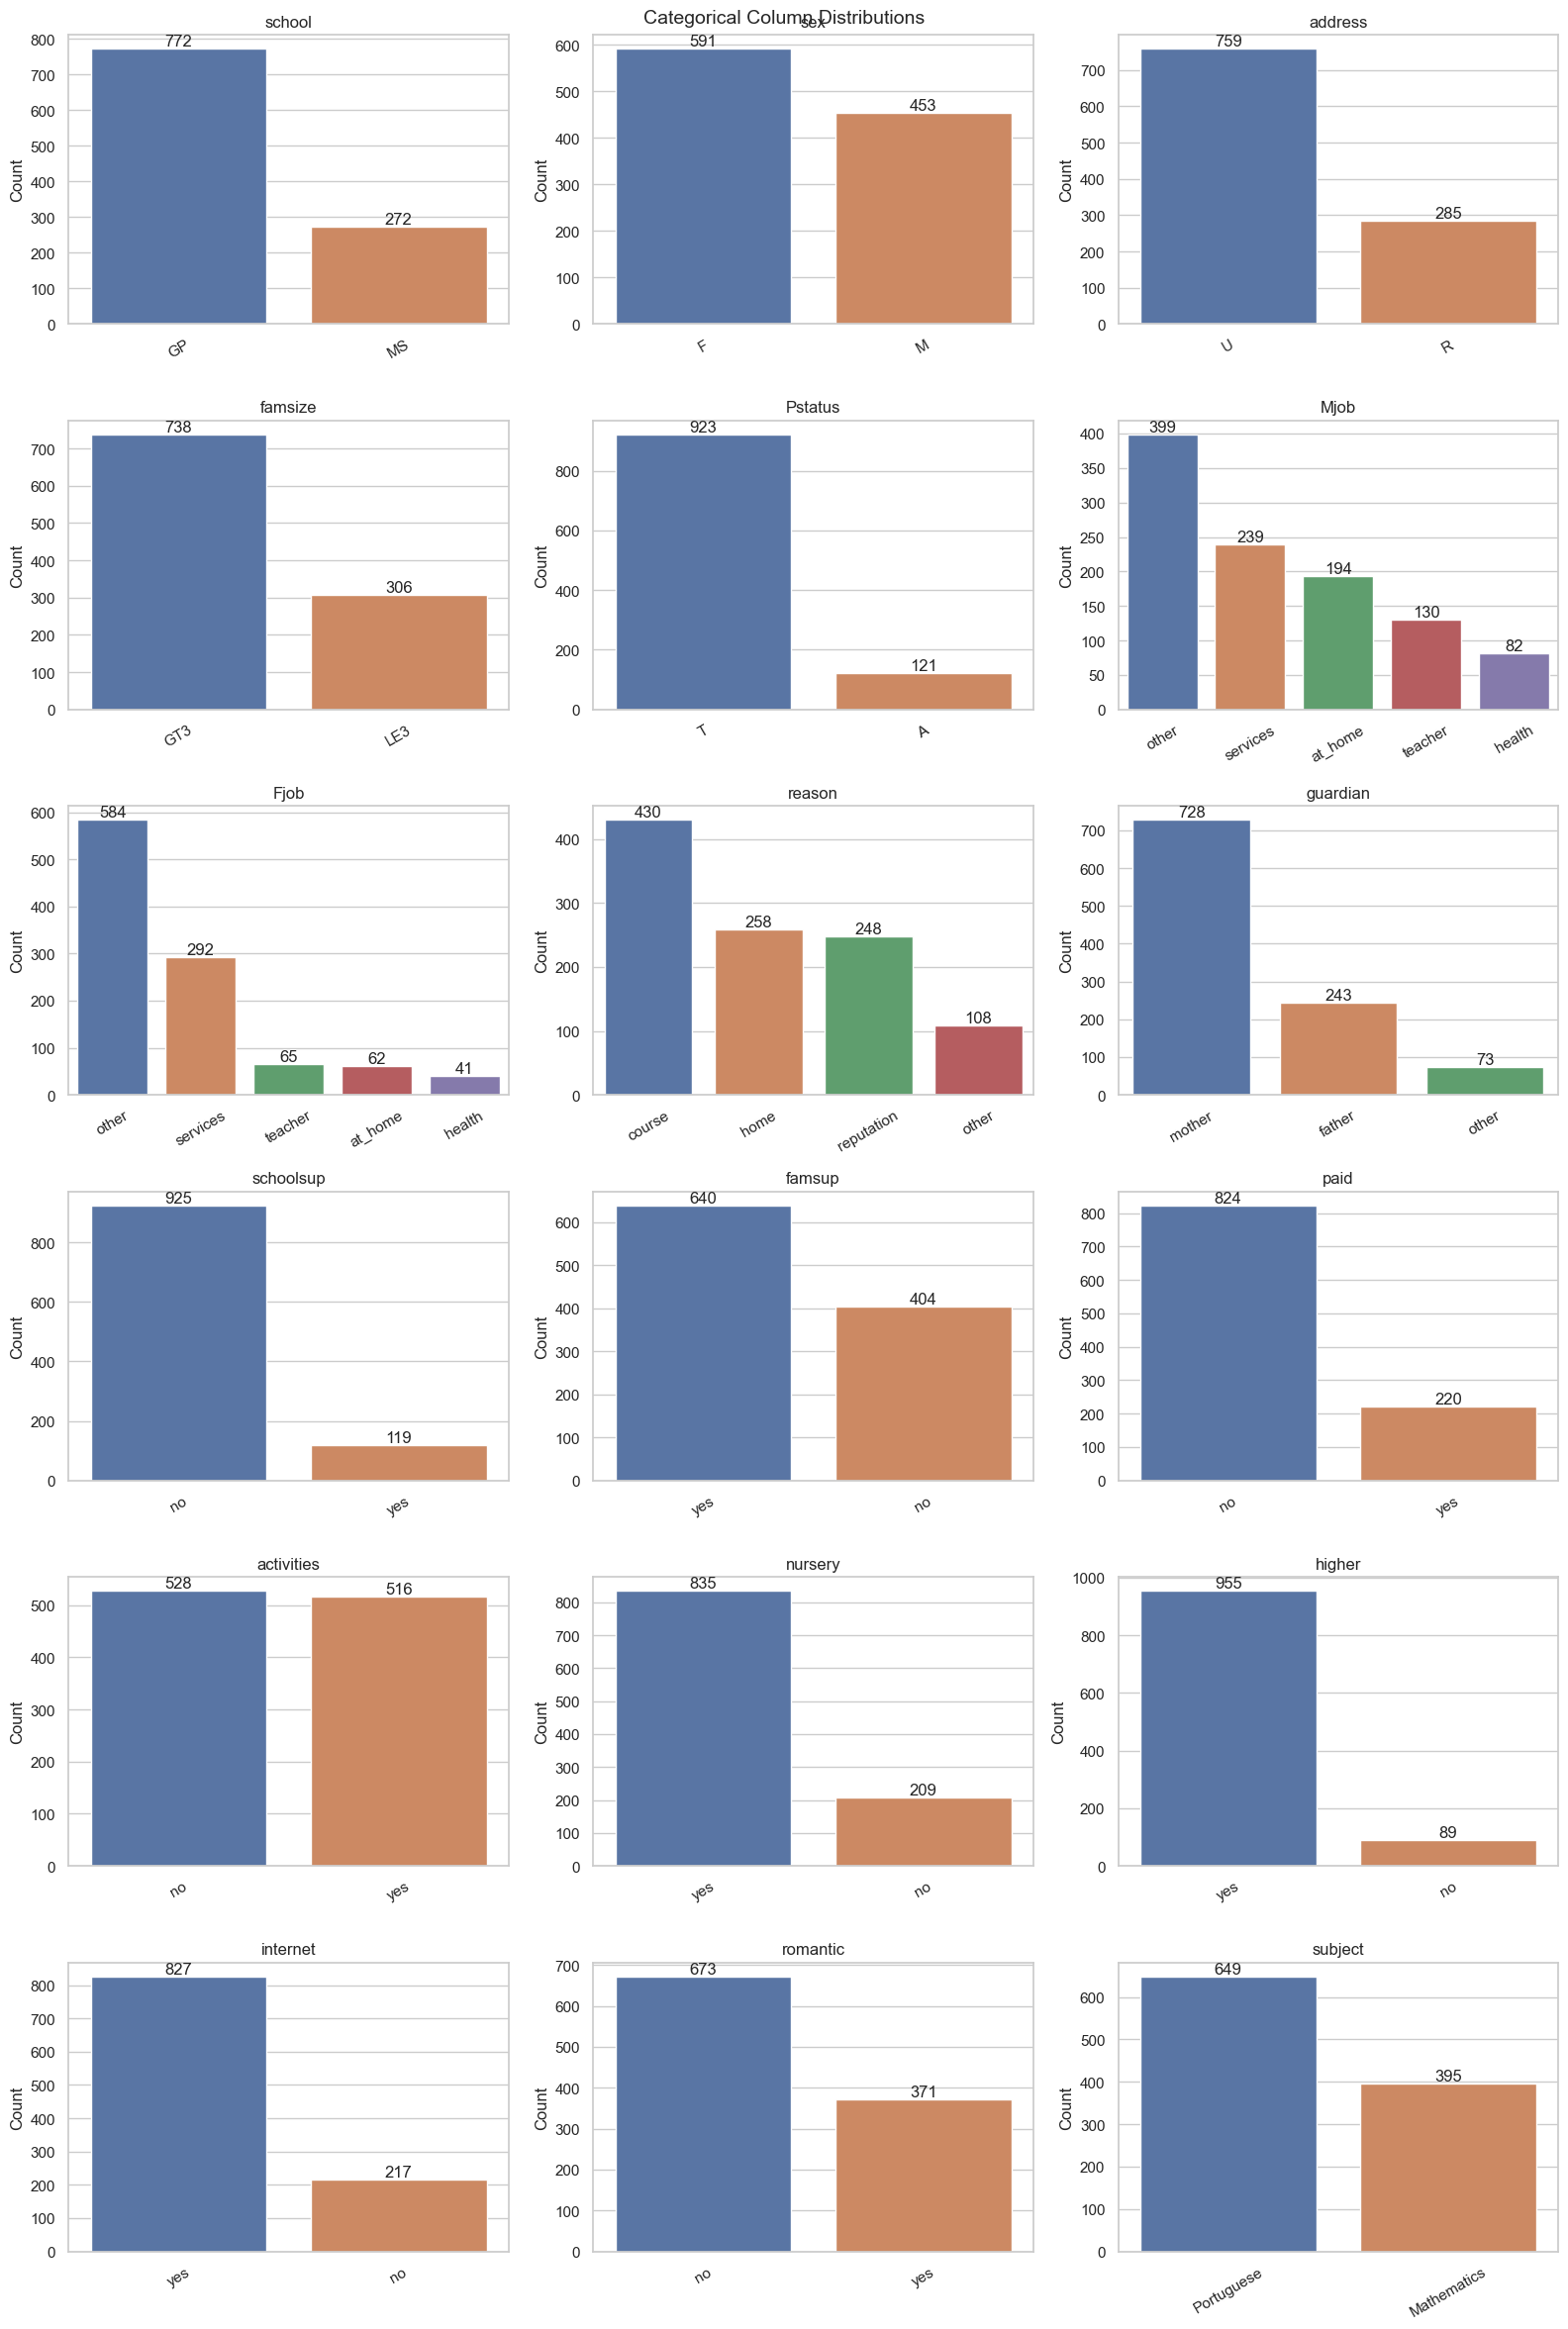

In [14]:
n_cols = 3
n_rows = (len(object_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, object_cols):

    # Create bar graph
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )

    # Add count on top of each bar
    for bar in ax.patches:
        ax.annotate(
            int(bar.get_height()),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom"
        )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

# Hide unused plots
for ax in axes[len(object_cols):]:
    ax.set_visible(False)

plt.suptitle("Categorical Column Distributions", fontsize=14)
plt.tight_layout()
plt.show()

## 1. Categorical Variables — Analysis

- The dataset is dominated by **GP school (772)**, **female students (591)**, and **urban students (759)**.
- Most students come from families with **more than 3 members (738)** and parents living together (**923**).
- `Mjob` and `Fjob` are mainly concentrated in the **other** and **services** categories.
- The most common reason for choosing the school is **course preference (430)**.
- Most students have their **mother as guardian (728)**.
- Most students attended nursery school (**835**) and want to pursue **higher education (955)**.
- Most students have **internet access at home (827)**.
- `activities` is almost evenly distributed between **yes (516)** and **no (528)**.
- More students are **not in a romantic relationship (673)**.
- Portuguese students (**649**) are more numerous than Mathematics students (**395**).

### Conclusion

> The categorical variables show some noticeable class imbalance, particularly for **school, address, guardian, nursery attendance, higher-education intention, and internet access**. These distributions should be considered during model development.

---

**Ordinal integer-coded columns** — these look numeric but are really small,
fixed rating/level scales (per the variable table above: 1-4 or 1-5 levels),
not counts you'd want to treat as continuous. Listing their exact value sets
the same way as the categorical columns above, since "what labels/levels exist"
matters here just as much.

In [15]:
ordinal_cols = [
    "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health"
]

for col in ordinal_cols:
    print(f"\n--- {col} ---")
    
    count = df[col].value_counts().sort_index()
    percent = (count / len(df) * 100).round(1)
    
    print(pd.DataFrame({
        "Count": count,
        "Percentage": percent
    }))


--- Medu ---
      Count  Percentage
Medu                   
0         9         0.9
1       202        19.3
2       289        27.7
3       238        22.8
4       306        29.3

--- Fedu ---
      Count  Percentage
Fedu                   
0         9         0.9
1       256        24.5
2       324        31.0
3       231        22.1
4       224        21.5

--- traveltime ---
            Count  Percentage
traveltime                   
1             623        59.7
2             320        30.7
3              77         7.4
4              24         2.3

--- studytime ---
           Count  Percentage
studytime                   
1            317        30.4
2            503        48.2
3            162        15.5
4             62         5.9

--- failures ---
          Count  Percentage
failures                   
0           861        82.5
1           120        11.5
2            33         3.2
3            30         2.9

--- famrel ---
        Count  Percentage
famrel         

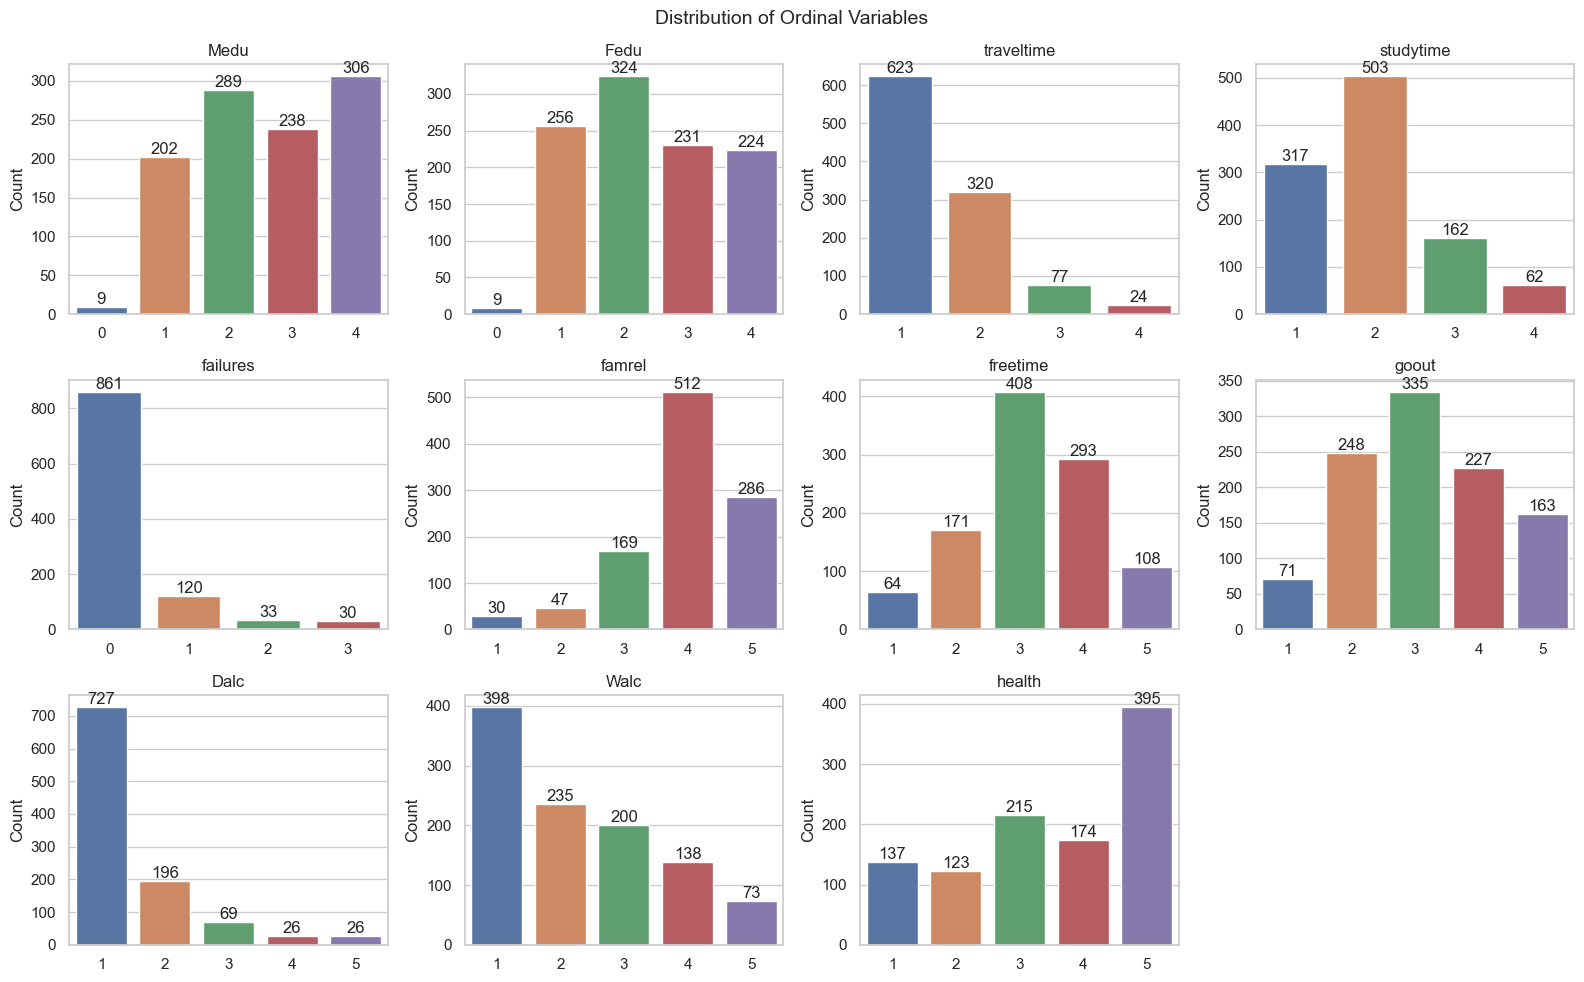

In [21]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, ordinal_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=ax
    )

    # Show count on top of each bar
    ax.bar_label(ax.containers[0], fmt="%d")

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

# Hide empty plots
for ax in axes[len(ordinal_cols):]:
    ax.set_visible(False)

plt.suptitle("Distribution of Ordinal Variables", fontsize=14)
plt.tight_layout()
plt.show()

several binary columns are heavily imbalanced in their own
right — e.g. most students report `internet="yes"` and `higher="yes"`, and
`romantic`/`paid`/`nursery` skew toward one label. That imbalance matters when
interpreting the risk-rate-by-category charts further down: a category with
very few students in it (e.g. `Fjob="health"` or `guardian="other"`) can show an
extreme-looking at_risk rate purely from small-sample noise, not a real effect —
worth checking the `count` column above before reading too much into any single
bar.

## Ordinal Variables — Analysis

- `Medu` and `Fedu` are mainly concentrated around **levels 2–4**, indicating moderate-to-higher parental education levels.
- `traveltime` is strongly concentrated at **level 1 (623)**, meaning most students have a short journey to school.
- `studytime` is highest at **level 2 (503)**, indicating moderate weekly study time is most common.
- `failures` is heavily concentrated at **0 (861)**, meaning most students have no previous failures.
- `famrel` is concentrated at **levels 4 and 5**, indicating generally good family relationships.
- `freetime` and `goout` are mainly concentrated around **level 3**, showing moderate free time and social activity.
- `Dalc` is strongly concentrated at **level 1**, while `Walc` is more evenly distributed across levels.
- `health` has the highest count at **level 5 (395)**.

### Conclusion

> The ordinal variables show that most students have **short travel times, moderate study and social activity, good family relationships, low workday alcohol consumption, and no previous academic failures**. Some variables, especially `failures`, `traveltime`, and `Dalc`, have highly uneven distributions.

#### 3. Grade distributions — G1, G2, G3

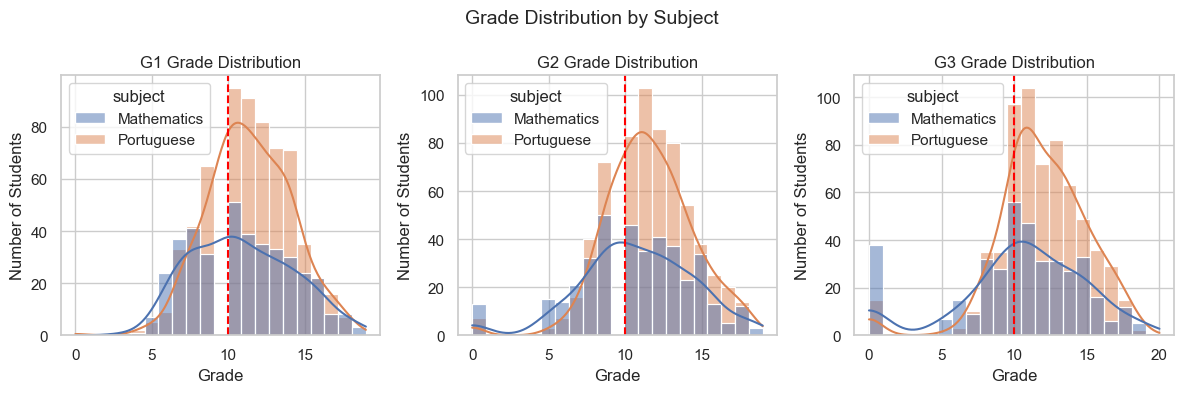

In [16]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, col in enumerate(["G1", "G2", "G3"]):
    sns.histplot(
        data=df,
        x=col,
        hue="subject",
        bins=21,
        kde=True,
        ax=axes[i]
    )

    axes[i].axvline(PASS_THRESHOLD, color="red", linestyle="--")
    axes[i].set_title(col + " Grade Distribution")
    axes[i].set_xlabel("Grade")
    axes[i].set_ylabel("Number of Students")

fig.suptitle("Grade Distribution by Subject", fontsize=14)
plt.tight_layout()
plt.show()

## 3. Grade Distribution by Subject — Analysis

- The distributions show the grades for **G1 (first period), G2 (second period), and G3 (final grade)** for Mathematics and Portuguese.
- The **Portuguese grade distribution is generally higher** than Mathematics across G1, G2, and G3.
- Most grades are concentrated around the **10–15 range**, particularly for Portuguese.
- Mathematics has a **wider and lower distribution**, with more students appearing around the lower grade ranges.
- The red dashed line represents the **pass threshold (10)**. A considerable number of students are below this threshold, especially in Mathematics.
- In **G3 (final grade)**, there is a noticeable group of Mathematics students with very low grades, including grades close to **0**.
- From G1 → G2 → G3, the overall distributions remain relatively similar, with Portuguese consistently showing higher grades.

### Conclusion

> The grade distributions indicate that **Portuguese students generally perform better than Mathematics students** across all three periods. A noticeable proportion of students are below the **pass threshold of 10**, with the risk being more evident in Mathematics. The final grade (`G3`) is therefore an important indicator for identifying students who may be academically at risk.

In [17]:
# Summary statistics by subject
df.groupby("subject")[["G1", "G2", "G3"]].describe().T

subject   Mathematics  Portuguese
G1 count   395.000000  649.000000
   mean     10.908861   11.399076
   std       3.319195    2.745265
   min       3.000000    0.000000
   25%       8.000000   10.000000
   50%      11.000000   11.000000
   75%      13.000000   13.000000
   max      19.000000   19.000000
G2 count   395.000000  649.000000
   mean     10.713924   11.570108
   std       3.761505    2.913639
   min       0.000000    0.000000
   25%       9.000000   10.000000
   50%      11.000000   11.000000
   75%      13.000000   13.000000
   max      19.000000   19.000000
G3 count   395.000000  649.000000
   mean     10.415190   11.906009
   std       4.581443    3.230656
   min       0.000000    0.000000
   25%       8.000000   10.000000
   50%      11.000000   12.000000
   75%      14.000000   14.000000
   max      20.000000   19.000000

In [18]:
# Create at-risk column
df["at_risk"] = (df["G3"] < PASS_THRESHOLD).astype(int)

# Calculate at-risk percentage by subject
at_risk_rate = df.groupby("subject")["at_risk"].mean() * 100

print("At-risk rate by subject:")
print(at_risk_rate.round(2))

At-risk rate by subject:
subject
Mathematics    32.91
Portuguese     15.41
Name: at_risk, dtype: float64


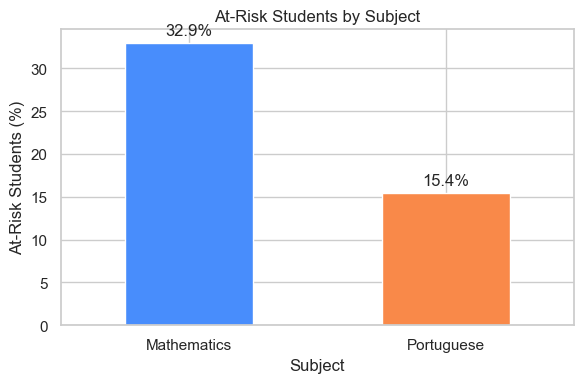

In [19]:
ax = at_risk_rate.plot(
    kind="bar",
    color=["#488DFC", "#F98949"],
    figsize=(6, 4),
    title="At-Risk Students by Subject"
)

# Add percentage labels on bars
for i, value in enumerate(at_risk_rate):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

ax.set_xlabel("Subject")
ax.set_ylabel("At-Risk Students (%)")
ax.set_xticklabels(["Mathematics", "Portuguese"], rotation=0)

plt.tight_layout()
plt.show()

## At-Risk Students by Subject — Analysis

- **Mathematics:** 32.9% of students are classified as at-risk because their final grade (`G3`) is below the pass threshold.
- **Portuguese:** 15.4% of students are classified as at-risk.
- Mathematics has a **much higher at-risk rate** than Portuguese.
- The difference is approximately **17.5 percentage points**, indicating a considerably higher academic risk in Mathematics.

### Conclusion

> The analysis shows that **Mathematics has a significantly higher proportion of at-risk students (32.9%) compared with Portuguese (15.4%)**. Therefore, Mathematics students may require more attention and early academic support in the student risk prediction system.

### 4. Absences

A meaningful number of `G3` scores are **0**, which in the UCI documentation
typically corresponds to students who withdrew or did not sit the final assessment
rather than a genuine bottom-of-scale grade — worth a sanity check before this feeds
`at_risk`.

In [20]:
zero_g3 = df[df["G3"] == 0]
print(f"Rows with G3 == 0: {len(zero_g3)} ({len(zero_g3)/len(df):.1%} of all rows)")
zero_g3.groupby("subject").size()

Rows with G3 == 0: 53 (5.1% of all rows)


subject
Mathematics    38
Portuguese     15
dtype: int64

Rows with G3 = 0: 53
Percentage: 5.1 %
subject
Mathematics    38
Portuguese     15
dtype: int64


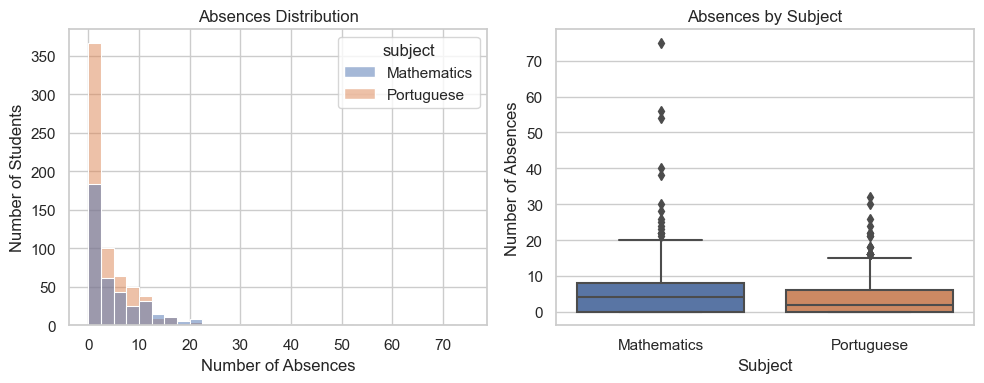

Absences Summary:
             count      mean       std  min  25%  50%  75%   max
subject                                                         
Mathematics  395.0  5.708861  8.003096  0.0  0.0  4.0  8.0  75.0
Portuguese   649.0  3.659476  4.640759  0.0  0.0  2.0  6.0  32.0


In [21]:
# Students with G3 = 0
zero_g3 = df[df["G3"] == 0]

print("Rows with G3 = 0:", len(zero_g3))
print("Percentage:", round(len(zero_g3) / len(df) * 100, 1), "%")

# Count G3 = 0 by subject
print(zero_g3.groupby("subject").size())

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Absences distribution
sns.histplot(data=df, x="absences", hue="subject", bins=30, ax=axes[0])
axes[0].set_title("Absences Distribution")
axes[0].set_xlabel("Number of Absences")
axes[0].set_ylabel("Number of Students")

# Absences by subject
sns.boxplot(data=df, x="subject", y="absences", ax=axes[1])
axes[1].set_title("Absences by Subject")
axes[1].set_xlabel("Subject")
axes[1].set_ylabel("Number of Absences")

plt.tight_layout()
plt.show()

# Summary statistics
print("Absences Summary:")
print(df.groupby("subject")["absences"].describe())

### Absences Distribution — Analysis

- Most students have a **low number of absences**, with the distribution heavily concentrated near 0–5 absences.
- The distribution is **right-skewed**, meaning a small number of students have much higher absences.
- Mathematics has a higher average number of absences (**5.71**) than Portuguese (**3.66**).
- The median is also higher for Mathematics (**4**) than Portuguese (**2**).
- Mathematics has a much wider range of absences, from **0 to 75**, while Portuguese ranges from **0 to 32**.
- The boxplot shows several **high-absence outliers**, particularly in Mathematics.
- There are **53 students (5.1%) with G3 = 0**:
  - Mathematics: **38**
  - Portuguese: **15**

### Conclusion

> Absences are generally low but highly right-skewed, with a small group of students having unusually high absence counts. **Mathematics students have higher average and median absences than Portuguese students**, and Mathematics also contains more extreme absence values. The presence of students with `G3 = 0` should be considered during further analysis because these cases may affect the interpretation of academic performance and risk prediction.

95% absence cutoff: 16
Students above cutoff: 37


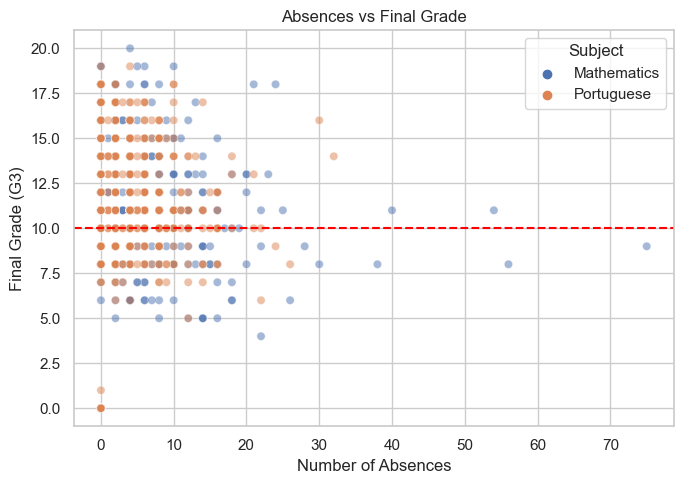

In [22]:
# Find high absence cutoff
cutoff = df["absences"].quantile(0.95)

print("95% absence cutoff:", round(cutoff))
print("Students above cutoff:", (df["absences"] > cutoff).sum())

# Scatter plot
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3",
    hue="subject",
    alpha=0.5
)

# Passing grade line
plt.axhline(PASS_THRESHOLD, color="red", linestyle="--")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.legend(title="Subject")

plt.tight_layout()
plt.show()

Most students have 0–15 absences.
Higher absences generally show a tendency toward lower final grades.
The red line represents the passing grade of 10.
Some students with high absences still pass, so absences are not the only factor affecting grades.
Mathematics and Portuguese show a similar pattern.

### 5. Failures (past class failures)

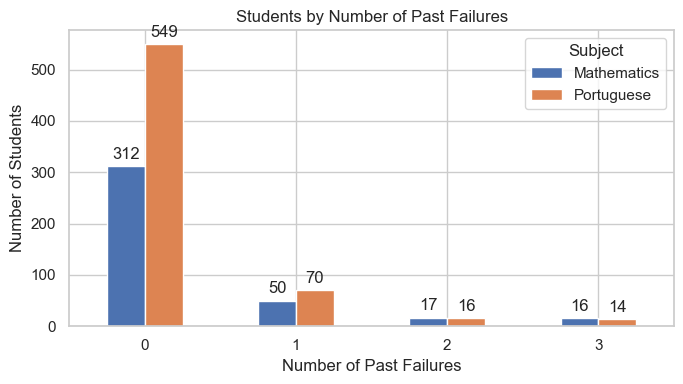

In [23]:
# Count students by subject and number of failures
fail_counts = df.groupby(["failures", "subject"]).size().unstack()

ax = fail_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Students by Number of Past Failures")
plt.xlabel("Number of Past Failures")
plt.ylabel("Number of Students")
plt.legend(title="Subject")
plt.xticks(rotation=0)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

## Past Failures — Analysis

### 1. Number of Students by Past Failures

- Most students have **0 previous failures**:
  - Mathematics: **312**
  - Portuguese: **549**
- The number of students decreases sharply as the number of past failures increases.
- Only a small number of students have **2 or 3 previous failures**.
- This indicates that the dataset is highly concentrated around **zero past failures**.

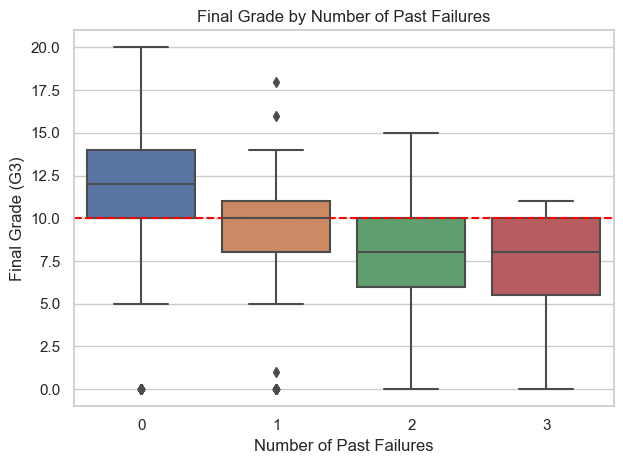

At-Risk Rate by Number of Past Failures:
failures
0    15.0
1    48.3
2    66.7
3    70.0
Name: at_risk, dtype: float64


In [24]:
sns.boxplot(data=df, x="failures", y="G3")

plt.axhline(PASS_THRESHOLD, color="red", linestyle="--")
plt.title("Final Grade by Number of Past Failures")
plt.xlabel("Number of Past Failures")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()

# At-risk rate
print("At-Risk Rate by Number of Past Failures:")
print((df.groupby("failures")["at_risk"].mean() * 100).round(1))

## Past Failures — Analysis

- Students with **0 past failures** have the lowest at-risk rate at **15%**.
- With **1 past failure**, the at-risk rate increases significantly to **48.3%**.
- With **2 past failures**, the rate increases further to **66.7%**.
- Students with **3 past failures** have the highest at-risk rate at **70%**.
- Therefore, the at-risk rate **increases consistently as the number of past failures increases**.

### Conclusion

> **Past failures are a strong indicator of academic risk.** Students with more previous failures are much more likely to fall below the pass threshold and may require additional academic support.

### 6. Study time

In [25]:
df["studytime"].value_counts().sort_index()


studytime
1    317
2    503
3    162
4     62
Name: count, dtype: int64

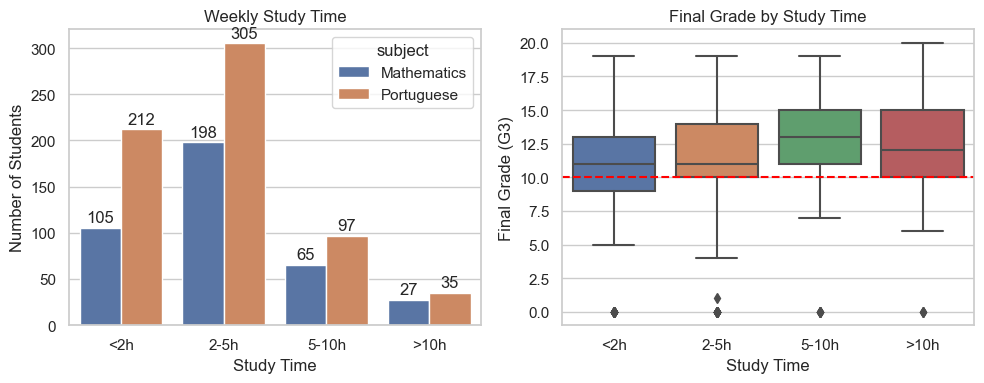

At-risk rate by study time:
                  mean  count
studytime_label              
<2h              0.274    317
2-5h             0.221    503
5-10h            0.142    162
>10h             0.145     62


In [28]:
# Convert studytime numbers to labels
labels = {
    1: "<2h",
    2: "2-5h",
    3: "5-10h",
    4: ">10h"
}

df["studytime_label"] = df["studytime"].map(labels)

order = ["<2h", "2-5h", "5-10h", ">10h"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Number of students
sns.countplot(
    data=df,
    x="studytime_label",
    hue="subject",
    order=order,
    ax=axes[0]
)

axes[0].set_title("Weekly Study Time")
axes[0].set_xlabel("Study Time")
axes[0].set_ylabel("Number of Students")


# Add count labels
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", padding=2)
# Grades
sns.boxplot(
    data=df,
    x="studytime_label",
    y="G3",
    order=order,
    ax=axes[1]
)

axes[1].axhline(PASS_THRESHOLD, color="red", linestyle="--")
axes[1].set_title("Final Grade by Study Time")
axes[1].set_xlabel("Study Time")
axes[1].set_ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()

# At-risk rate
print("At-risk rate by study time:")
print(
    df.groupby("studytime_label")["at_risk"]
    .agg(["mean", "count"])
    .reindex(order)
    .round(3)
)

## Weekly Study Time — Analysis

- Most students study **2–5 hours per week**, with **198 Mathematics** and **305 Portuguese** students in this category.
- The **<2 hours** category is the second most common, with **105 Mathematics** and **212 Portuguese** students.
- Relatively few students study **more than 10 hours** per week: **27 Mathematics** and **35 Portuguese** students.
- The number of students decreases as study time increases beyond the **2–5 hour** range.

### Final Grade vs Study Time

- Students studying **<2 hours** have a lower median final grade, around **11**.
- The median grade increases to around **11–12** for students studying **2–5 hours**.
- Students studying **5–10 hours** have a higher median grade of around **13**.
- Students studying **>10 hours** have a median grade around **12**, showing that the highest study-time group does not have the highest median.
- The red dashed line represents the **pass threshold of 10**. The median grade for all study-time groups is above this threshold.
- Some students in every study-time category have very low grades, including grades close to **0**.

### Conclusion

> The analysis suggests that **moderate-to-high study time is generally associated with better final grades**. Students studying **5–10 hours per week** show the highest median performance, while students studying **less than 2 hours** have comparatively lower grades. However, the relationship is not strictly linear, as studying more than 10 hours does not result in a higher median grade.

### 7. Correlations — and the target-leakage check

**Per the implementation plan's Target Leakage Warning:** `G3` is the same
student's later grade as `G1`/`G2`, and `at_risk` is derived directly from `G3`. So
`G3` (and by extension anything that is just a proxy for it) must **never** be used
as an input feature alongside `at_risk` as the target. This section computes the
full correlation matrix for context, but the feature set for modeling must stop at
`G1`, `G2`, and the non-grade features — never `G3`.

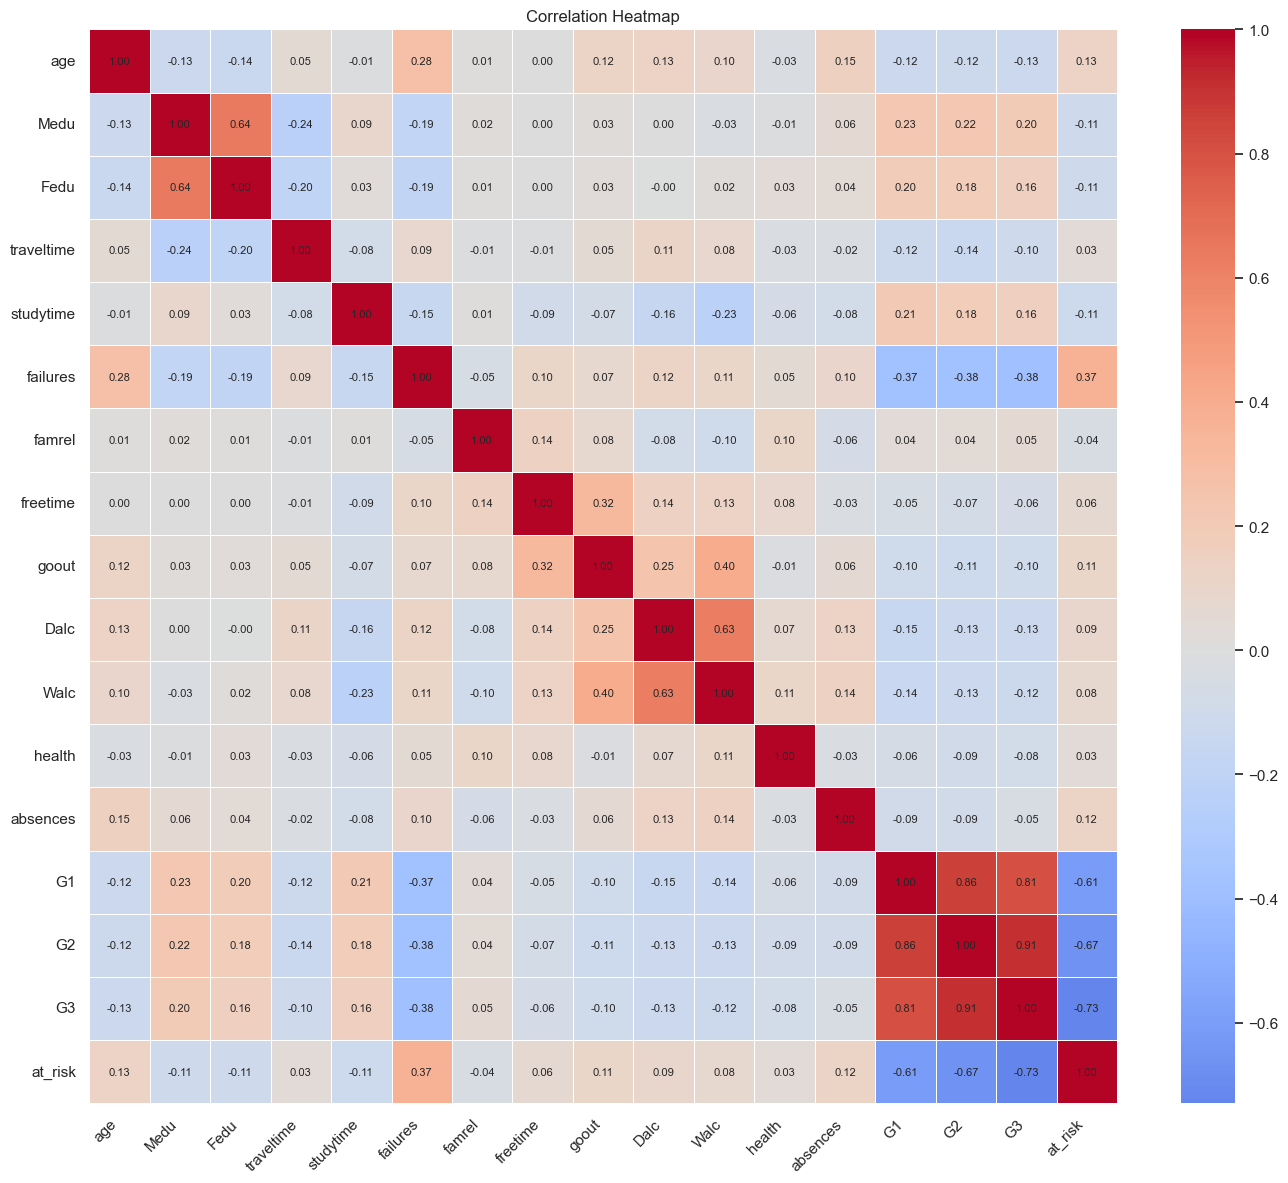

In [29]:
corr = df.select_dtypes("number").corr()

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    ax=ax
)

# Add correlation value to every cell
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(
            j + 0.5,
            i + 0.5,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set_title("Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## Correlation Heatmap — Analysis

- `G1`, `G2`, and `G3` have a **strong positive correlation** with each other. Students who perform well in one period generally perform well in the other periods.
- `G3` has a **negative correlation with `at_risk`**, because students with higher final grades are less likely to be classified as at-risk.
- `failures` has a **negative relationship with G1, G2, and G3**. Students with more previous failures tend to have lower grades.
- `Medu` and `Fedu` show a **positive correlation**, meaning parents' education levels tend to be related.
- `Dalc` and `Walc` have a **strong positive correlation**, indicating that students who report higher workday alcohol consumption also tend to report higher weekend consumption.
- Most other variables have **weak correlations** with the grades, suggesting that their individual linear relationship with academic performance is limited.
- `age`, `travel time`, `health`, `freetime`, and `absences` show relatively weak correlations with `G3`.

### Conclusion

> The strongest relationships in the dataset are between **G1, G2, and G3**, making previous-period grades important indicators of final performance. **Past failures are negatively associated with academic performance**, while `at_risk` is strongly related to the final grade because it is derived directly from `G3`. Therefore, these variables should be considered carefully when building the student risk prediction model.

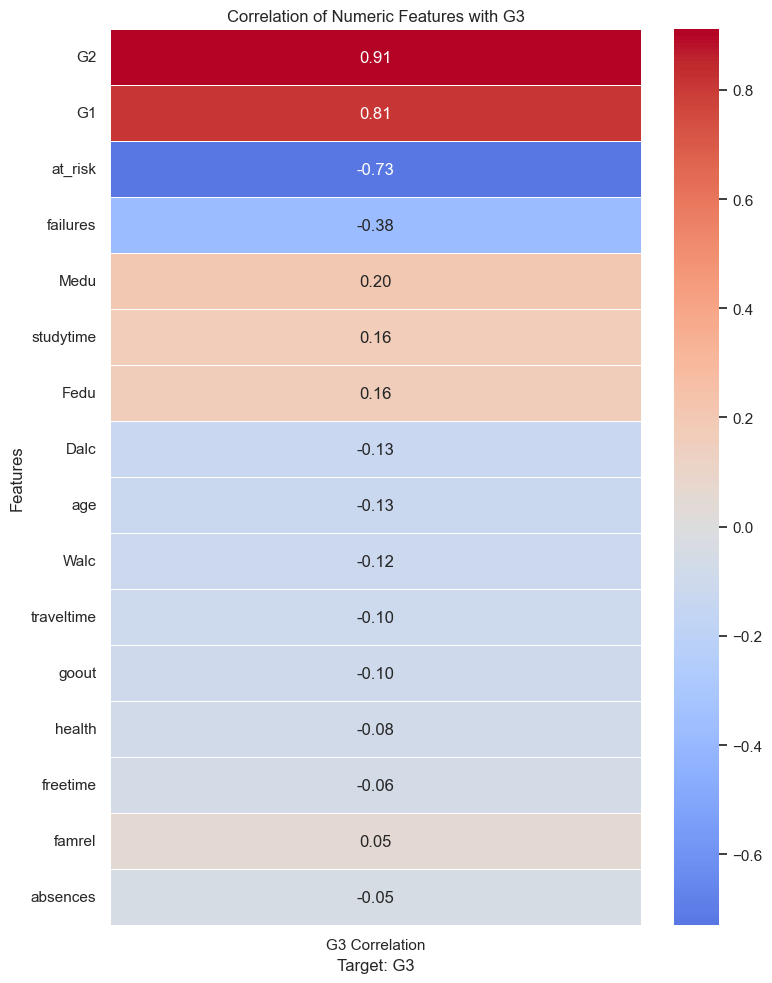

In [30]:
# Correlation of numeric features with G3
numeric_cols = df.select_dtypes(include=[np.number]).columns

g3_corr = (
    df[numeric_cols]
    .corr()["G3"]
    .drop("G3")
    .sort_values(key=np.abs, ascending=False)
)

# Plot G3 correlations as a heatmap
fig, ax = plt.subplots(figsize=(8, 10))

sns.heatmap(
    g3_corr.to_frame(name="G3 Correlation"),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Correlation of Numeric Features with G3")
ax.set_xlabel("Target: G3")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

As expected, `G1` and `G2` are by far the strongest correlates of `G3` (~0.8-0.9) —
exactly the temporal leakage the plan calls out. `failures` and `absences` are the
strongest **non-grade** signals, which lines up with Sections 4-5 above. This
confirms the plan's recommended safe feature set:

```
features = {G1, G2, absences, studytime, failures, ...other demographic/social}
target   = at_risk   (derived from G3, G3 itself dropped from features)
```

### 8. Quick categorical look (context for `build_uci_features()`)

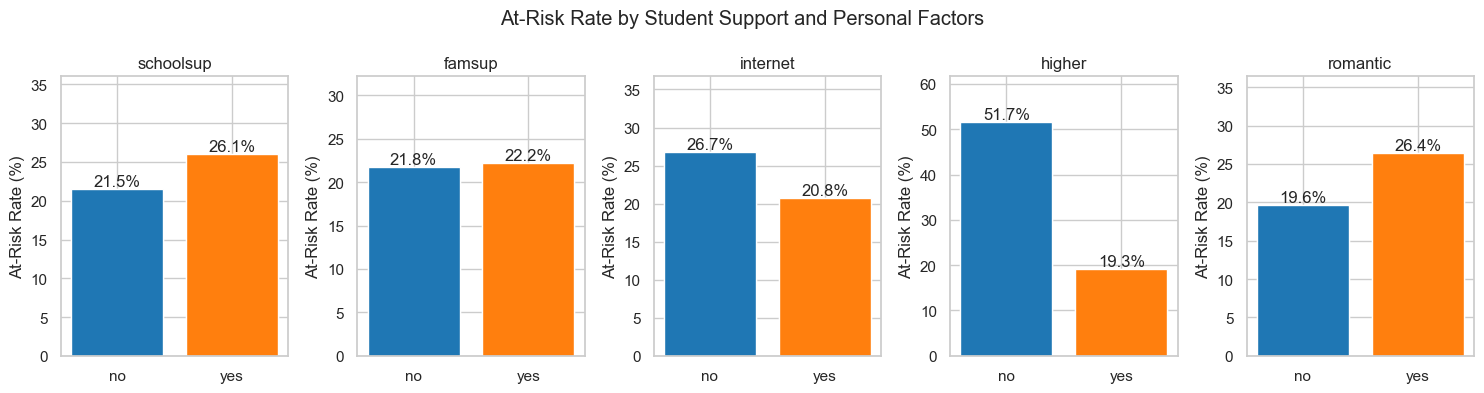

In [31]:
cat_cols = ["schoolsup", "famsup", "internet", "higher", "romantic"]

fig, axes = plt.subplots(1, len(cat_cols), figsize=(15, 4) )

for ax, col in zip(axes, cat_cols):
    rate = df.groupby(col)["at_risk"].mean() * 100

    bars = ax.bar(rate.index, rate.values)

    # Automatic different colors
    colors = plt.cm.tab10(range(len(rate)))
    
    bars = ax.bar(rate.index, rate.values, color=colors)

    # Add percentage on top of bars
    for bar, value in zip(bars, rate.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}%",
            ha="center",
            va="bottom"
        )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("At-Risk Rate (%)")
    ax.set_ylim(0, max(rate.values) + 10)

plt.suptitle("At-Risk Rate by Student Support and Personal Factors")
plt.tight_layout()
plt.show()

### 9. Risk rate by category — broad sweep

Section 8 above already checked 5 columns. Here's the same `show_bar_rate()`
helper run across **every** binary/nominal categorical column in the dataset —
`sex`, `school`, `address`, `famsize`, `Pstatus`, `Mjob`, `Fjob`, `reason`,
`guardian` — so no categorical column is left unchecked for a risk association.
Per the label-imbalance note in Section 2b, read the smaller-count bars (e.g.
individual `Mjob`/`Fjob` categories) with extra caution.

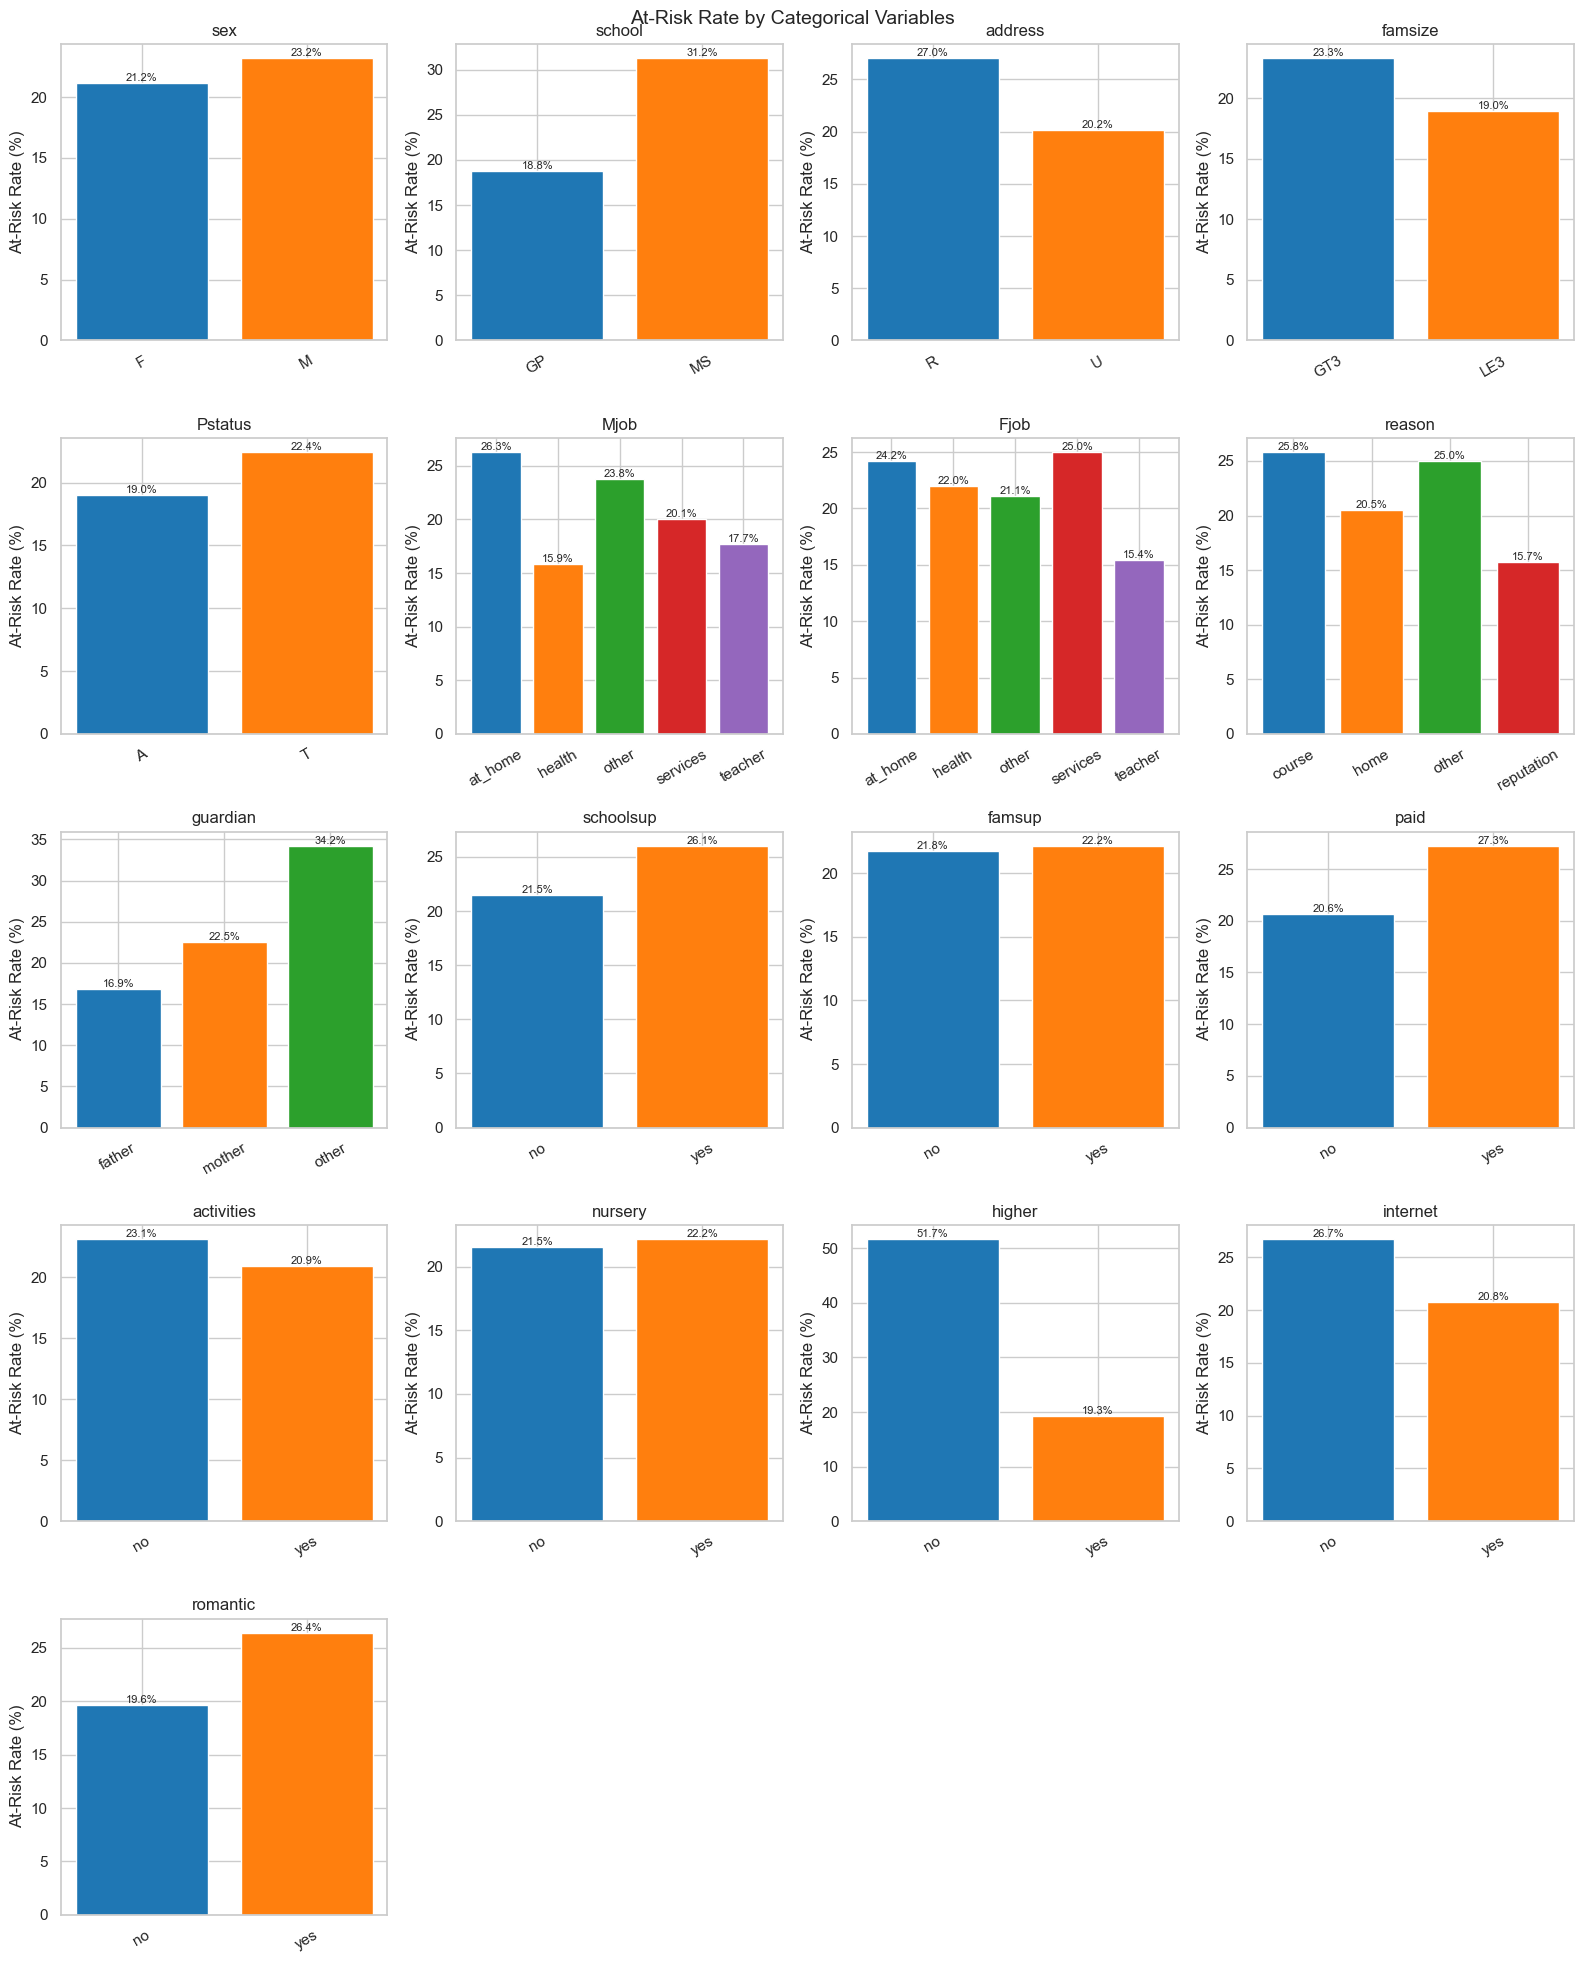

In [35]:
all_cat_cols = [
    "sex", "school", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian",
    "schoolsup", "famsup", "paid", "activities", "nursery",
    "higher", "internet", "romantic"
]

n_cols = 4
n_rows = (len(all_cat_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, all_cat_cols):

    rate = df.groupby(col)["at_risk"].mean() * 100

    # Automatic different colors
    colors = plt.cm.tab10(range(len(rate)))

    bars = ax.bar(rate.index, rate.values, color=colors)

    # Add percentage on top
    for bar, value in zip(bars, rate.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("At-Risk Rate (%)")
    ax.tick_params(axis="x", rotation=30)

# Hide unused plots
for ax in axes[len(all_cat_cols):]:
    ax.axis("off")

plt.suptitle("At-Risk Rate by Categorical Variables", fontsize=14)
plt.tight_layout()
plt.show()

## Analysis

- **Higher education** shows the strongest difference: students not interested in higher education have a **51.7%** at-risk rate vs **19.3%** for those interested.
- **School type** also differs significantly: **MS (31.2%)** vs **GP (18.8%)**.
- **Guardian** shows variation, with **Other (34.2%)** having the highest at-risk rate.
- **No internet access (26.7%)** and **rural students (27.0%)** show higher risk rates.
- **Paid activities (27.3%)** and being in a **romantic relationship (26.4%)** are also associated with higher risk.
- Variables such as **sex, family support, nursery, and activities** show relatively smaller differences.

## Conclusion

The analysis suggests that **higher-education aspiration, school, guardian, internet access, and social/family factors** are useful categorical indicators of student risk.

> These are **associations, not causal relationships**. They should be combined with academic and engagement features for the final ML-based risk prediction model.

### 10. Pair plot — grades, absences, failures, studytime vs. at_risk

Scatter-matrix of the core grade/risk-related numeric features, colored by
`at_risk`. Good for spotting relationships a single correlation number can
hide (e.g. non-linear separations, or clusters that only show up when two
features are viewed together).

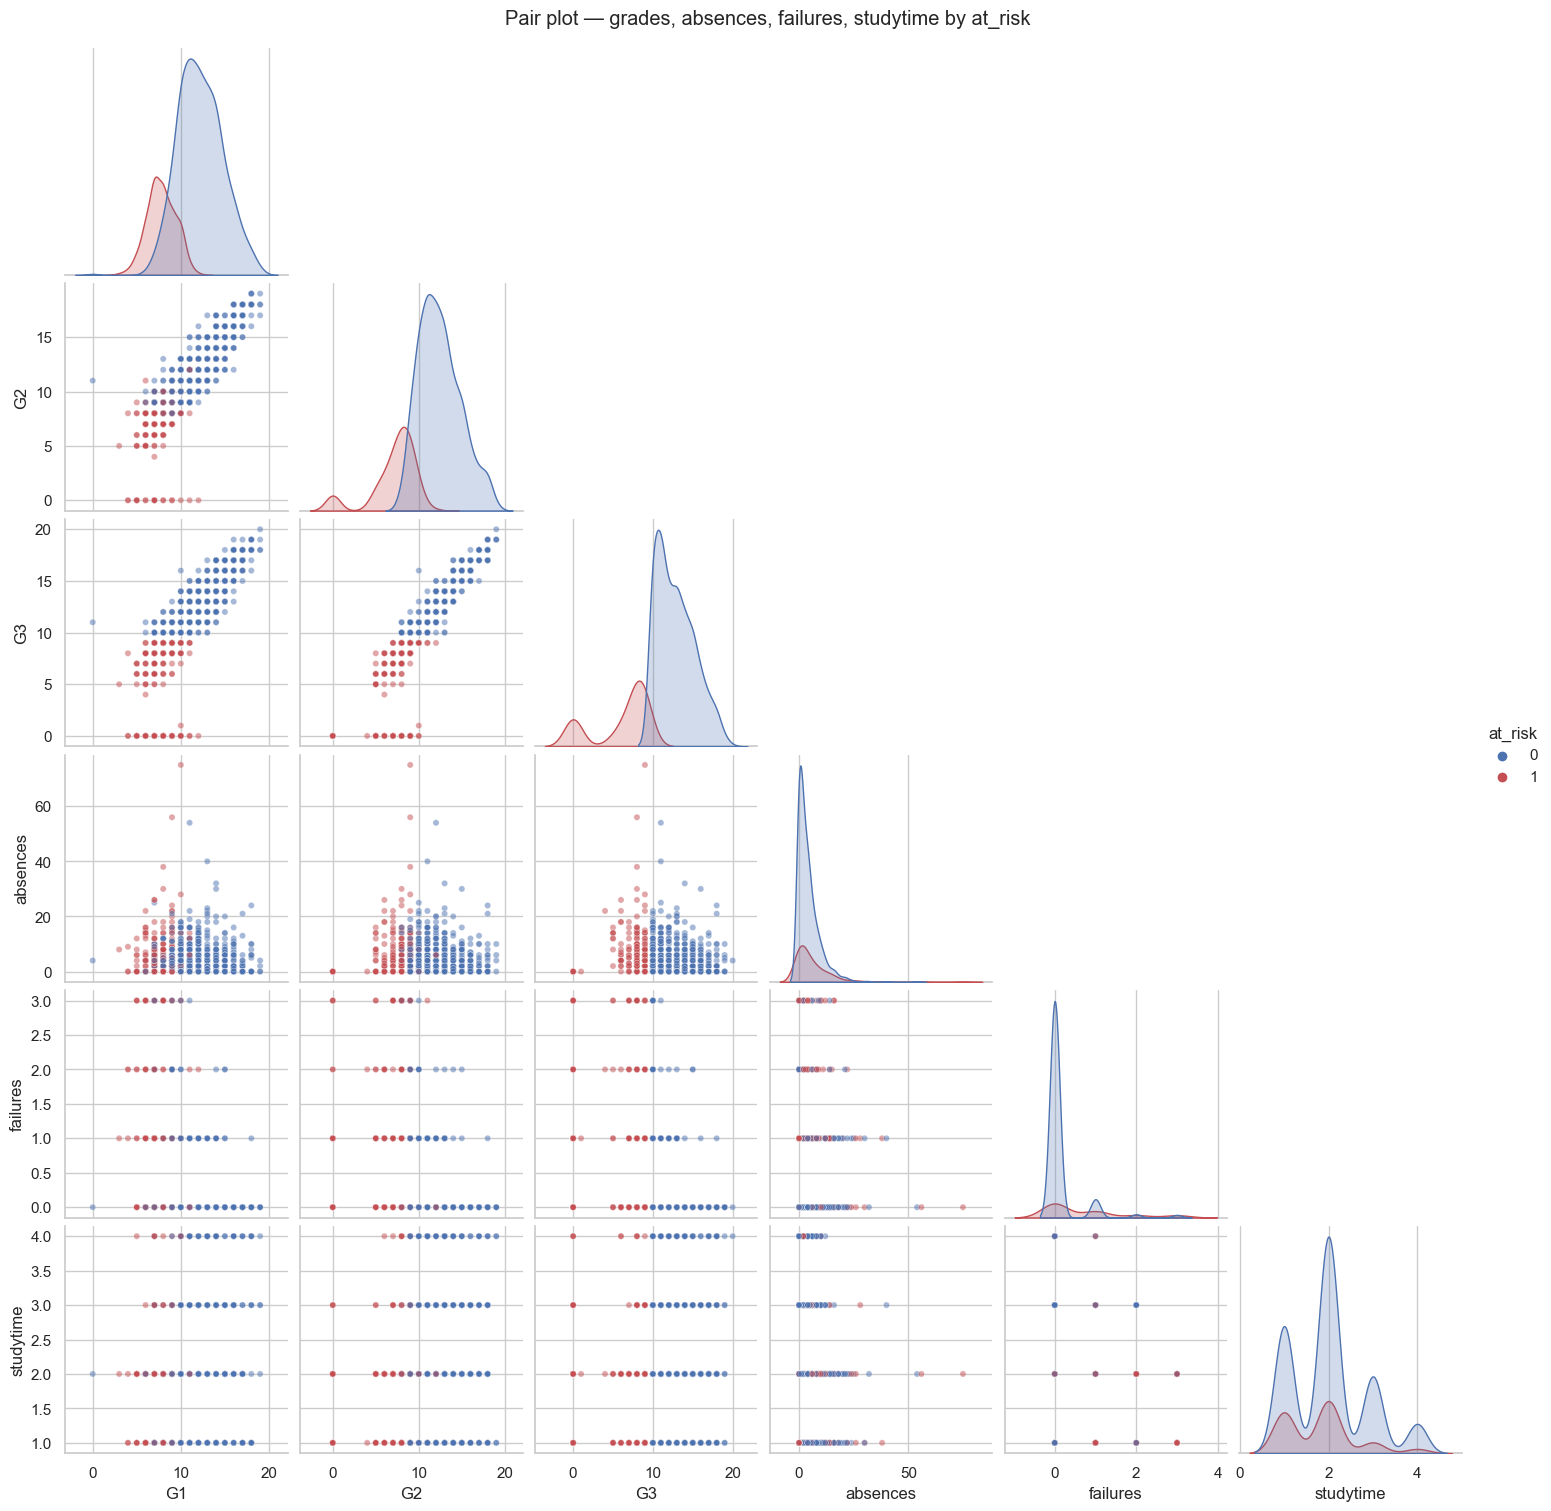

In [36]:
pairplot_cols = ["G1", "G2", "G3", "absences", "failures", "studytime", "at_risk"]
sns.pairplot(
    df[pairplot_cols],
    hue="at_risk",
    diag_kind="kde",
    corner=True,
    palette={0: "#4C72B0", 1: "#C44E52"},
    plot_kws={"alpha": 0.5, "s": 20},
)
plt.suptitle("Pair plot — grades, absences, failures, studytime by at_risk", y=1.01)
plt.show()

## Analysis

- **G1, G2, and G3 grades** show a clear separation between at-risk and non-risk students.
- At-risk students generally have **lower grades**, especially in G2 and G3.
- **G1, G2, and G3 are strongly positively related** — students performing well in one period tend to perform well in later periods.
- **Absences** are generally higher among at-risk students, although there is considerable overlap between the two groups.
- Students with **more previous failures** tend to have a higher likelihood of being at risk.
- **Study time** shows some difference, but the overlap between groups is large, suggesting a weaker relationship than grades and failures.

## Conclusion

**Previous grades (G1–G3) appear to be the strongest indicators of student risk**, followed by previous failures and absences. Study time shows a comparatively weaker separation.

> Academic performance and previous failures should therefore receive higher importance in the student risk prediction model.

### 11. Violin plots — distribution shape, not just spread

Boxplots (used earlier) show quartiles; violin plots additionally show where
the distribution is *dense* — useful for spotting bimodal patterns (e.g. a
cluster of very-low scorers plus a separate cluster of typical scorers) that a
boxplot's five-number summary would flatten out.

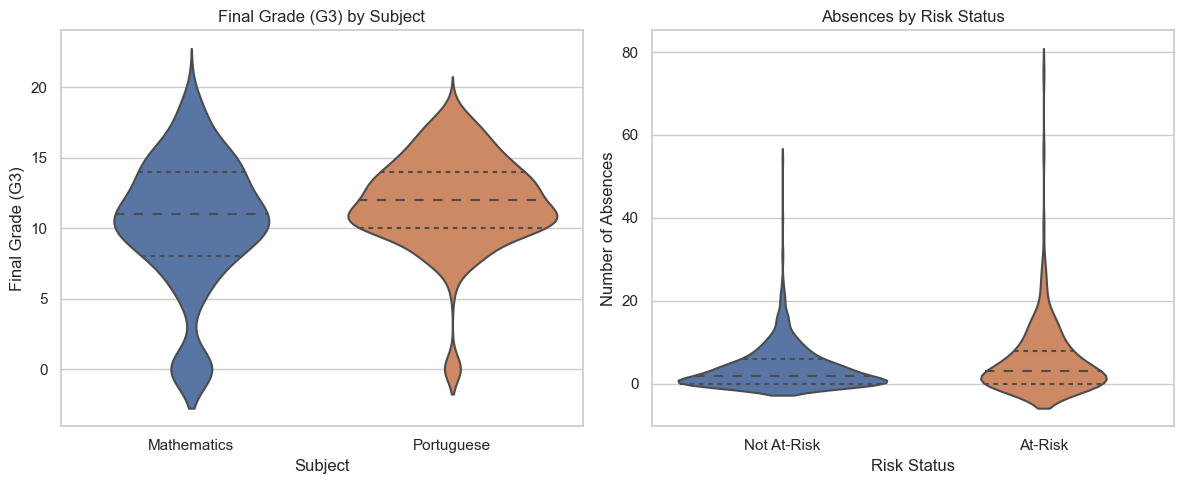

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Final grade by subject
sns.violinplot(
    data=df,
    x="subject",
    y="G3",
    inner="quartile",
    ax=axes[0]
)

axes[0].set_title("Final Grade (G3) by Subject")
axes[0].set_xlabel("Subject")
axes[0].set_ylabel("Final Grade (G3)")


# Absences by risk
sns.violinplot(
    data=df,
    x="at_risk",
    y="absences",
    inner="quartile",
    ax=axes[1]
)

axes[1].set_title("Absences by Risk Status")
axes[1].set_xlabel("Risk Status")
axes[1].set_ylabel("Number of Absences")

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Not At-Risk", "At-Risk"])

plt.tight_layout()
plt.show()

###  Violin Plot — Final Grade and Absences by Risk Status

### Analysis
- Mathematics and Portuguese have broadly similar **G3 distributions**.
- At-risk students generally have **lower final grades**.
- At-risk students show a wider distribution of **absences**.
- Most students have low absences, but high-absence cases are more visible among at-risk students.

### Conclusion
> **Lower grades and higher absences are associated with increased student risk.**


### 12. Count plots — how common is each label, by subject

Section 9 showed *risk rate* per category. This shows the *raw counts* per
category, split by subject — needed to judge whether a subject difference in
risk rate (e.g. from Section 9) reflects a real behavioral difference or just a
different mix of students taking each subject.

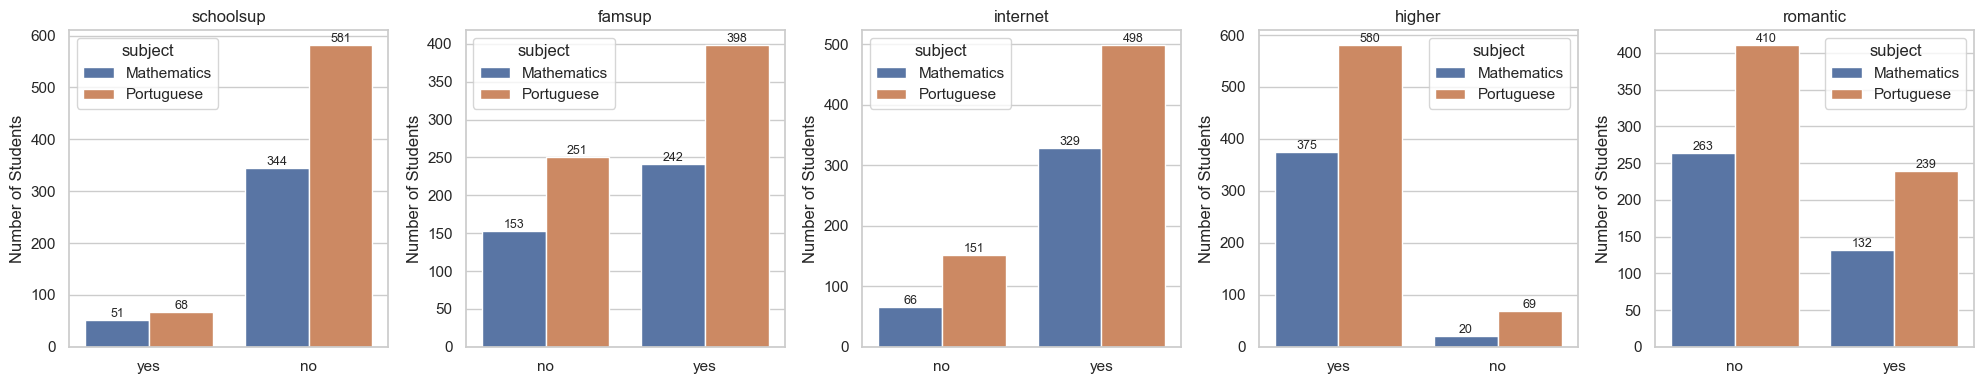

In [38]:
count_cols = ["schoolsup", "famsup", "internet", "higher", "romantic"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, col in zip(axes, count_cols):

    sns.countplot(
        data=df,
        x=col,
        hue="subject",
        ax=ax
    )

    # Add count on top of each bar
    for bar in ax.patches:
        ax.annotate(
            f"{int(bar.get_height())}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

### Categorical Variables — Student Counts by Subject

### Analysis
- Portuguese has more observations than Mathematics across the categorical variables.
- Most students have **internet access** and want **higher education**.
- Students receiving school or family support form smaller groups.
- Students without a romantic relationship are more numerous.

### Conclusion
> **Categorical variables provide useful student background information, but should be combined with academic and behavioral features for risk prediction.**

---

### 13. Outlier detection (IQR method) + skewness

IQR-based bounds (`Q1 - 1.5*IQR`, `Q3 + 1.5*IQR`) for the columns most likely to
have extreme values — `absences`, `G3`, `failures`, `age`. Skewness quantifies
the same right-tail pattern seen visually in earlier histograms as a single
number (>1 is heavily right-skewed, ~0 is roughly symmetric).

In [39]:
outlier_cols = ["absences", "G3", "failures", "age"]
outlier_rows = [outlier_summary(df, col) for col in outlier_cols]
outlier_df = pd.DataFrame(outlier_rows).set_index("column")
outlier_df

,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,pct_outliers,skewness
column,,,,,,,,
absences,0.0,6.0,6.0,-9.0,15.0,54,5.17,3.74
G3,10.0,14.0,4.0,4.0,20.0,54,5.17,-0.99
failures,0.0,0.0,0.0,0.0,0.0,183,17.53,2.78
age,16.0,18.0,2.0,13.0,21.0,2,0.19,0.43


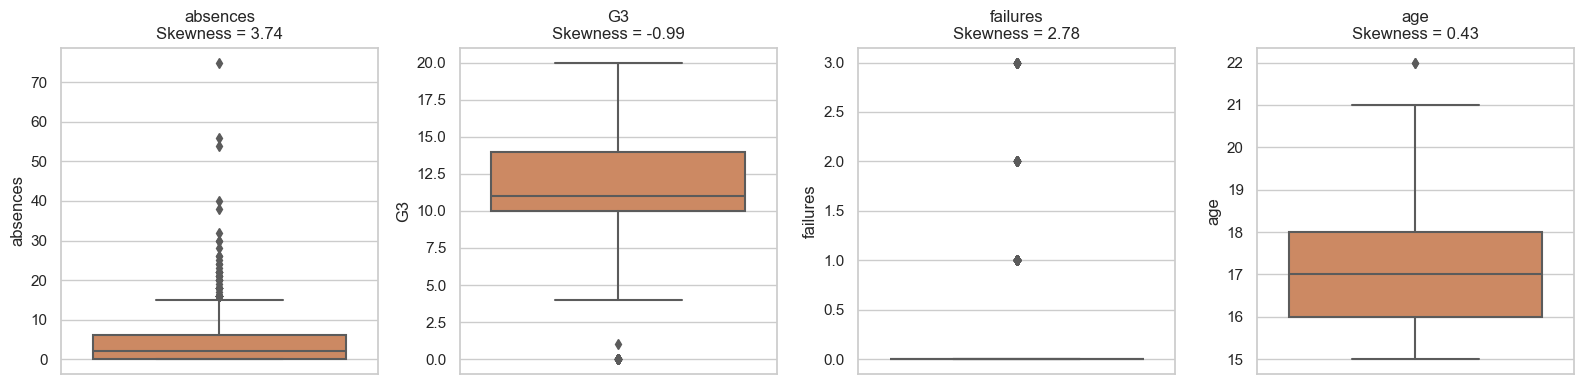

In [40]:
fig, axes = plt.subplots(1, len(outlier_cols), figsize=(4 * len(outlier_cols), 4))

for ax, col in zip(axes, outlier_cols):
    sns.boxplot(data=df, y=col, ax=ax, color="#DD8452")
    ax.set_title(f"{col}\nSkewness = {df[col].skew():.2f}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

### Distribution Analysis — Absences, G3, Failures and Age

### Analysis
- **Absences** are highly right-skewed (**3.74**), with most students having low absences and a few having very high values.
- **Failures** are also right-skewed (**2.78**), with most students having zero failures.
- **G3** has negative skewness (**-0.99**), indicating more students are concentrated toward higher grades.
- **Age** has relatively low skewness (**0.43**) and mainly ranges from 15–22.

### Conclusion
> **Absences and failures contain significant skewness and outliers, so they should be handled carefully during preprocessing and model training.**

---

### 14. Risk summary table — multiple categories at once

A single pivot combining two categorical dimensions (`sex` × `school`) against
`at_risk` rate and sample size — useful for spotting whether an effect seen in
one column (e.g. sex) holds consistently across the other (school), or is
actually concentrated in just one combination.

In [41]:
risk_summary = (
    df.groupby(["sex", "school"])["at_risk"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "at_risk_rate"})
    .round(3)
)
risk_summary

at_risk_rate  count
sex school                     
F   GP             0.181    420
    MS             0.287    171
M   GP             0.196    352
    MS             0.356    101

### 15. Correlation by subject — do Math and Portuguese behave the same?

Math and Portuguese are different subjects with different student populations
(Section 3 already found different `at_risk` rates between them) — worth
checking whether the *feature-to-target relationships* also differ, not just
the raw rates.

           Mathematics  Portuguese
G1               0.801       0.826
G2               0.905       0.919
absences         0.034      -0.091
failures        -0.360      -0.393
studytime        0.098       0.250
age             -0.162      -0.107


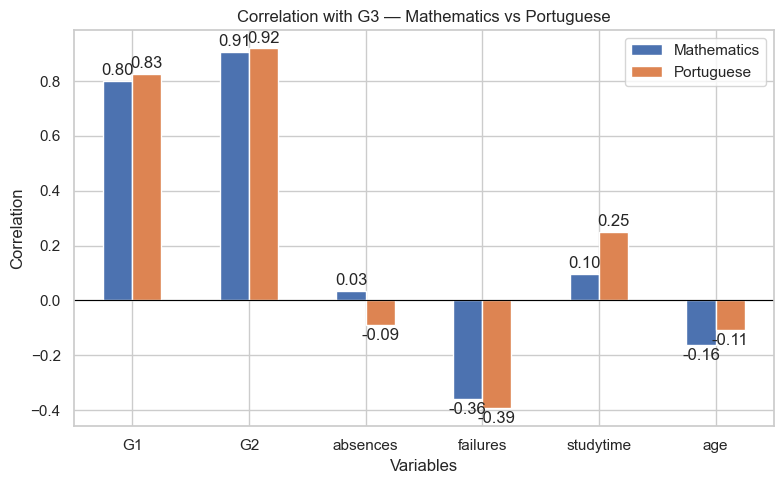

In [42]:
corr_cols = ["G1", "G2", "absences", "failures", "studytime", "age", "G3"]

# Correlation with final grade
math_corr = mat[corr_cols].corr()["G3"].drop("G3")
por_corr = por[corr_cols].corr()["G3"].drop("G3")

comparison = pd.DataFrame({
    "Mathematics": math_corr,
    "Portuguese": por_corr
}).round(3)

print(comparison)

# Plot
ax = comparison.plot(kind="bar", figsize=(8, 5))

ax.set_title("Correlation with G3 — Mathematics vs Portuguese")
ax.set_xlabel("Variables")
ax.set_ylabel("Correlation")
ax.axhline(0, color="black", linewidth=0.8)

# Add values on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation with G3 — Mathematics vs Portuguese

### Analysis
- **G2** has the strongest correlation with G3: **0.91 (Math)** and **0.92 (Portuguese)**.
- **G1** also has a strong positive correlation: **0.80** and **0.83**.
- **Failures** have a moderate negative correlation: **-0.36** and **-0.39**.
- **Study time** has a weak positive correlation.
- **Absences** have very weak correlation with G3.
- Age shows a weak negative relationship with G3.

### Conclusion
> **Previous academic performance, especially G2, is the strongest indicator of final grade, while previous failures negatively affect performance.**

---

### 16. Absences, failures, and study time vs. risk — split by subject

Same three relationships as Sections 4-6 of the original EDA, this time
faceted by `subject` side by side, to check whether the pattern (not just the
overall rate) holds the same way in both.

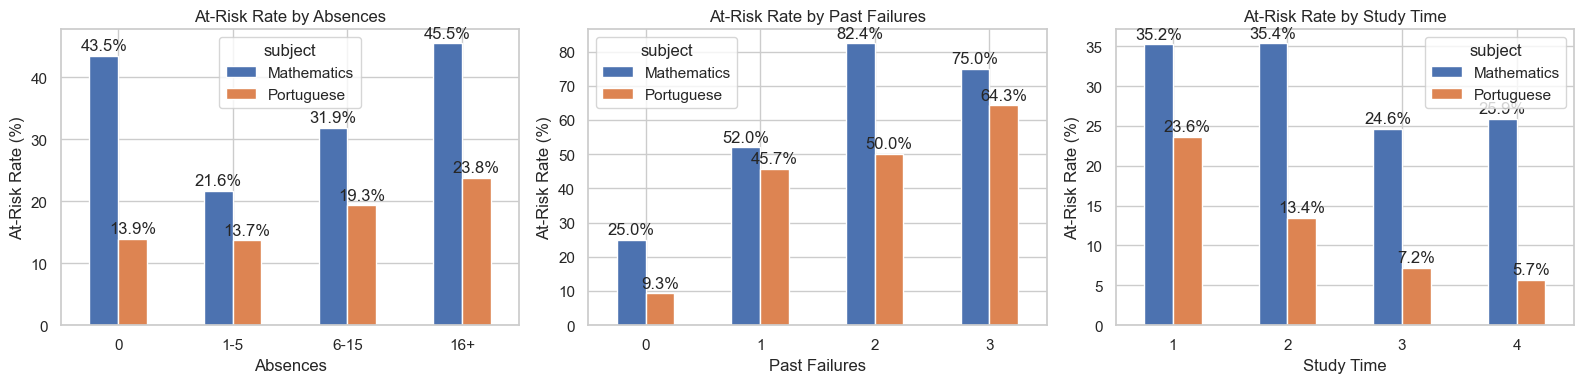

In [43]:
# Create absence groups
df["absence_bucket"] = pd.cut(
    df["absences"],
    bins=[-1, 0, 5, 15, 100],
    labels=["0", "1-5", "6-15", "16+"]
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. At-risk rate by absences
risk = df.groupby(
    ["absence_bucket", "subject"], observed=True
)["at_risk"].mean() * 100

risk.unstack().plot(kind="bar", ax=axes[0])

axes[0].set_title("At-Risk Rate by Absences")
axes[0].set_xlabel("Absences")
axes[0].set_ylabel("At-Risk Rate (%)")
axes[0].tick_params(axis="x", rotation=0)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=2)


# 2. At-risk rate by failures
risk = df.groupby(
    ["failures", "subject"]
)["at_risk"].mean() * 100

risk.unstack().plot(kind="bar", ax=axes[1])

axes[1].set_title("At-Risk Rate by Past Failures")
axes[1].set_xlabel("Past Failures")
axes[1].set_ylabel("At-Risk Rate (%)")
axes[1].tick_params(axis="x", rotation=0)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2)


# 3. At-risk rate by study time
risk = df.groupby(
    ["studytime", "subject"]
)["at_risk"].mean() * 100

risk.unstack().plot(kind="bar", ax=axes[2])

axes[2].set_title("At-Risk Rate by Study Time")
axes[2].set_xlabel("Study Time")
axes[2].set_ylabel("At-Risk Rate (%)")
axes[2].tick_params(axis="x", rotation=0)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.1f%%", padding=2)


plt.tight_layout()
plt.show()

### At-Risk Rate by Absences, Past Failures and Study Time

### Analysis
- Higher **absences** generally increase the at-risk rate, especially in Mathematics.
- At-risk rates increase strongly with the number of **past failures**.
- Students with **3 previous failures** show very high risk.
- **Study time** does not show a consistent relationship with risk across both subjects.

### Conclusion
> **Past failures are a strong risk indicator, while high absences also contribute to increased risk. Study time alone is not a reliable predictor.**

---

### 17. Parent education vs. risk

`Medu`/`Fedu` (mother's/father's education, 0=none to 4=higher education) as a
socioeconomic-adjacent signal — checking whether more-educated parents
correlates with lower `at_risk` rates for their children.

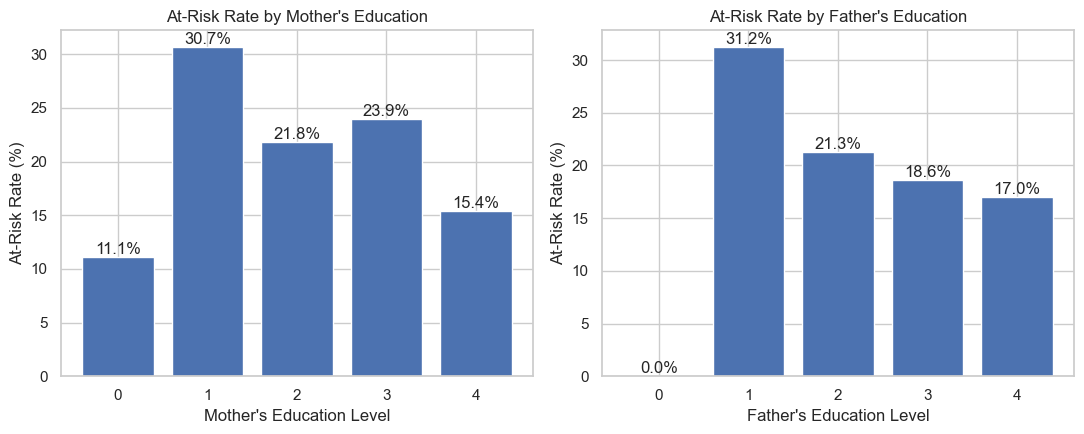

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Mother's education
rate = df.groupby("Medu")["at_risk"].mean() * 100
bars = axes[0].bar(rate.index, rate.values)

for bar, value in zip(bars, rate.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

axes[0].set_title("At-Risk Rate by Mother's Education")
axes[0].set_xlabel("Mother's Education Level")
axes[0].set_ylabel("At-Risk Rate (%)")


# Father's education
rate = df.groupby("Fedu")["at_risk"].mean() * 100
bars = axes[1].bar(rate.index, rate.values)

for bar, value in zip(bars, rate.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

axes[1].set_title("At-Risk Rate by Father's Education")
axes[1].set_xlabel("Father's Education Level")
axes[1].set_ylabel("At-Risk Rate (%)")

plt.tight_layout()
plt.show()

### 18. Age distribution vs. final grade

Older students in this dataset are often repeat students (linked to past
`failures`) — checking whether `age` alone shows a grade pattern, or whether
it's really `failures` doing the work (older == more likely to have failed a
grade before, not older == inherently lower-performing).

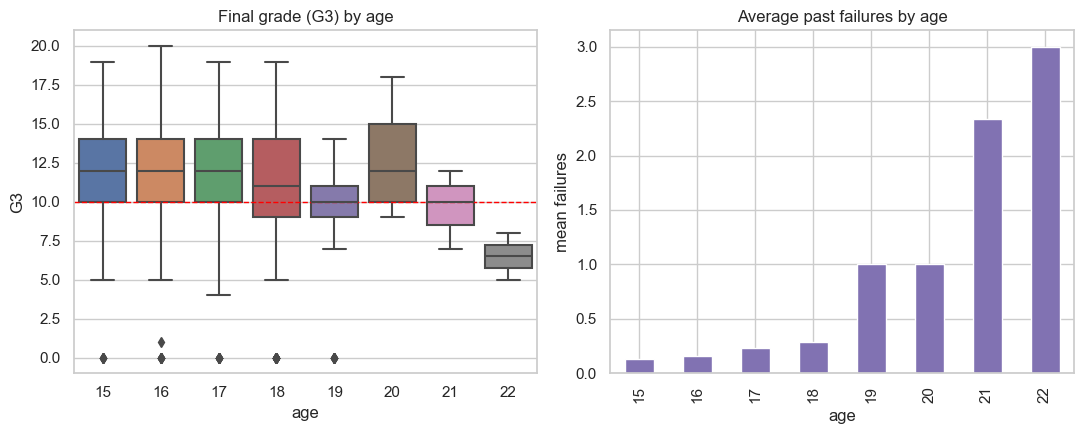

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.boxplot(data=df, x="age", y="G3", ax=axes[0])
axes[0].axhline(PASS_THRESHOLD, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Final grade (G3) by age")

age_failures = df.groupby("age")["failures"].mean()
age_failures.plot(kind="bar", ax=axes[1], color="#8172B2")
axes[1].set_title("Average past failures by age")
axes[1].set_ylabel("mean failures")

plt.tight_layout()
plt.show()

### Final Grade and Past Failures by Age

### Analysis
- Students aged **15–20** generally show higher final-grade distributions.
- Students aged **21–22** tend to have lower final grades.
- Average past failures increase noticeably with age, particularly after age 19.
- Age 22 has the highest average number of past failures.

### Conclusion
> **Older students in this dataset tend to have more previous failures and lower final grades, making age a potentially useful supporting feature for risk prediction.**
